# 1. Parsivar utilizing inspect: cleaning misspleings in the comments, usign Parsivar

### imports

In [1]:
import sys

import duckdb

print("Python:", sys.version)
print("DuckDB:", duckdb.__version__)
print("Executable:", sys.executable)


# If this fails after a successful install, restart the kernel and run this cell again
# import parsivar

# print("Parsivar imported from:", parsivar.__file__)


from pathlib import Path

cwd = Path.cwd()
ROOT = cwd.parent if cwd.name == "notebooks" else cwd

CSV_PATH = ROOT / "data" / "raw" / "digikala-comments.csv"
DB_PATH = ROOT / "project.duckdb"

print("ROOT:", ROOT)
print("CSV exists:", CSV_PATH.exists())
print("DuckDB version:", duckdb.__version__)


con = duckdb.connect(str(DB_PATH))
con.execute("LOAD ui;")
con.execute("CALL start_ui();")


Python: 3.12.16 (main, Oct 26 2026, 14:08:45) [Clang 23.1.3 ]
DuckDB: 2.0.0
Executable: /home/alireza/AI-Bootcamp/Project-3-digikala-review/digikala-review-transformer/.venv/bin/python
ROOT: /home/alireza/AI-Bootcamp/Project-3-digikala-review/digikala-review-transformer
CSV exists: True
DuckDB version: 2.0.0


# the Database

In [2]:
print(con.sql("SHOW TABLES").df())

Opening in existing browser session.
                 name
0   body_backup_latin
1          clean_base
2     defect_manifest
3            dup_plan
4         dup_plan_s3
5          len_sample
6                 raw
7        rule_summary
8      tmp_dup_groups
9         tmp_dup_ids
10       tmp_dup_rows


[1:1:0100/000000.756156:ERROR:content/zygote/zygote_main_linux.cc:197] Failed sending zygote boot message: Broken pipe (32)
[381926:381926:0100/000000.769468:ERROR:content/zygote/zygote_linux.cc:662] write: Broken pipe (32)


In [3]:
TABLE = "clean_base"

print(con.sql(f"DESCRIBE {TABLE}").df()[["column_name", "column_type"]])
print(con.sql(f"SELECT count(*) AS n_rows FROM {TABLE}").df())

# Reproducible random sample of 10 rows
sample = con.sql(
    f"SELECT * FROM {TABLE} USING SAMPLE reservoir(10 ROWS) REPEATABLE (42)"
).df()

for text in sample["body"]:  # change "body" if your column has another name
    print(repr(text))
    print("---")

             column_name    column_type
0               _row_idx         BIGINT
1                     id        VARCHAR
2                  title        VARCHAR
3                   rate  DECIMAL(10,2)
4  recommendation_status        VARCHAR
5             product_id        VARCHAR
6               is_buyer        VARCHAR
7            seller_code        VARCHAR
8            rating_band        VARCHAR
9                   body        VARCHAR
    n_rows
0  6151947
'بهترین کتابی که خوندم همینه داستان بین شمس و مولانا انقدر خوب نوشته شده که حس و حال و کامل به خواننده القا کنه'
---
'راضی کننده بود'
---
'عالی'
---
'مناسب پوستهای روشن'
---
'تخفیف بزنید لطفا'
---
'برای پوست من خیلی خوب بود'
---
'بوی خوب و قیمت عالی کلا راضی ام'
---
'ماسک اشتباهی برام فرستادن'
---
'بوش فوق العادست ماندگاریشم نسبت به قیمت خوبه'
---
'خوب'
---


# Parsivar Resources download

In [4]:
# import shutil
# import time
# import urllib.request
# import zipfile
# from pathlib import Path

# import parsivar

# SPELL_URL = "https://www.dropbox.com/s/tlyvnzv1ha9y1kl/spell.zip?dl=1"  # compare with the README link
# EXT_DIR = ROOT / "data" / "external"
# EXT_DIR.mkdir(parents=True, exist_ok=True)
# ZIP_PATH = EXT_DIR / "parsivar_spell.zip"
# EXTRACT_DIR = EXT_DIR / "parsivar_spell_extracted"

# # Keep the zip outside .venv so it survives reinstalls
# if not ZIP_PATH.exists():
#     req = urllib.request.Request(SPELL_URL, headers={"User-Agent": "Mozilla/5.0"})
#     with urllib.request.urlopen(req) as resp, open(ZIP_PATH, "wb") as f:
#         shutil.copyfileobj(resp, f)

# if not zipfile.is_zipfile(ZIP_PATH):
#     ZIP_PATH.unlink()  # do not keep a bad download (probably an HTML page)
#     raise RuntimeError("Downloaded file is not a zip. Download it manually into data/external/")

# shutil.rmtree(EXTRACT_DIR, ignore_errors=True)
# with zipfile.ZipFile(ZIP_PATH) as zf:
#     zf.extractall(EXTRACT_DIR)

# # Use the "spell" folder if the archive has one, otherwise the archive root
# candidates = [p for p in EXTRACT_DIR.rglob("spell")
#               if p.is_dir() and "__MACOSX" not in p.parts]
# src = candidates[0] if candidates else EXTRACT_DIR

# dest = Path(parsivar.__file__).parent / "resource" / "spell"
# shutil.copytree(src, dest, dirs_exist_ok=True)
# print("Copied to:", dest)
# for p in sorted(dest.iterdir()):
#     print(f"  {p.name}  ({p.stat().st_size / 1e6:.1f} MB)")

# from parsivar import SpellCheck

# t0 = time.time()
# spell = SpellCheck()
# print(f"SpellCheck loaded in {time.time() - t0:.1f}s")
# print(spell.spell_corrector("نمازگذاران وارد مسلی شدند."))
# # README expects: نمازگزاران وارد مصلی شدند .

# handmaid instances before running on DB

In [5]:
# import html
# import re
# from difflib import SequenceMatcher

# import pandas as pd
# from IPython.display import HTML, display

# PAIRS = [
#     ("کیفیت ساخت این گوشی خیلی خوب است.", "کیفیط ساخت این گوشی خیلی خوب است."),
#     ("بسته‌بندی محصول مناسب بود و آسیبی ندیده بود.", "بسته‌بندی محسول مناسب بود و آسیبی ندیده بود."),
#     ("قیمت این کالا نسبت به کیفیتش منصفانه است.", "قیمت این کالا نسبت به کیفیتش منصفاه است."),
#     ("صفحه نمایش روشن و واضح است ولی باتری زود تمام می‌شود.", "صفحه نمایش روشن و واضح است ولی باتری زوود تمام می‌شود."),
#     ("ارسال سریع بود و پیک با احترام برخورد کرد.", "ارسال سریغ بود و پیک با احترام برخورد کرد."),
#     ("این دستگاه برای استفاده روزمره بسیار کاربردی است.", "این دستگاه برای استفاده روزمره بسیار کاربدی است."),
#     ("رنگ محصول کاملاً مطابق عکس‌ها بود.", "رنگ محصول کاملاً مطابغ عکس‌ها بود."),
#     ("از خرید این محصول پشیمان نشدم.", "از خرید این محصل پشیمان نشدم."),
#     ("ولی کیفیت صدا در بلندگوی آن ضعیف است.", "ولی کیفت صدا در بلندگوی آن ضعیف است."),
#     ("مدل قبلی بهتر بود و این نسخه تغییر چندانی ندارد.", "مدل قبلی بهتز بود و این نسخه تغییر چندانی ندارد."),
#     ("تحویل از دیجی‌کالا خیلی سریع انجام شد.", "تحویل از دیجی‌کالا خیلی سریع انجاام شد."),
#     ("این کفش راحت است اما سایزش کمی بزرگ است.", "این کفش راخت است اما سایزش کمی بزرگ است."),
#     ("متاسفانه دوربین شب خوبی ندارد.", "متاسقانه دوربین شب خوبی ندارد."),
#     ("هدفون‌ها بی‌سیم هستند و اتصالشان پایدار است.", "هدفون‌ها بی‌سیم هستند و اتصالشان پایدر است."),
#     ("کیفیت پارچه خوب است ولی دوخت‌ها ضعیف هستند.", "کیفیت پارچه خوب است ولی دوخت‌ها ضعیب هستند."),
# ]

# PUNCT_SPACE = re.compile(r"\s+([.،!؟:;])")


# def canon(text):
#     """Ignore spacing differences (e.g. the space Parsivar adds before a period)."""
#     if text is None:
#         return None
#     return " ".join(PUNCT_SPACE.sub(r"\1", text).split())


# def fix(text):
#     """Return (corrected_text, status). Never raises."""
#     if text is None:
#         return None, "null"
#     try:
#         return spell.spell_corrector(text), "ok"
#     except Exception as exc:
#         return None, f"error: {str(exc)[:200]}"


# # ---------- RTL HTML display helpers (reused in later cells) ----------
# RTL_CSS = """
# <style>
# .rtl-table {border-collapse: collapse; width: 100%; font-size: 15px;
#             background: #fff; color: #000;}
# .rtl-table th, .rtl-table td {border: 1px solid #999; padding: 6px 10px; vertical-align: top;}
# .rtl-table th {background: #eee;}
# .rtl-table td.fa {direction: rtl; text-align: right;
#                   font-family: Vazirmatn, Tahoma, "DejaVu Sans", sans-serif;}
# .rtl-table .del {background: #ffc9c9;}
# .rtl-table .ins {background: #b7f0b7;}
# </style>
# """


# def diff_html(before, after):
#     """Return (before_html, after_html) with changed words highlighted."""
#     wb = canon(before).split()
#     wa = canon(after).split()
#     sm = SequenceMatcher(a=wb, b=wa, autojunk=False)
#     out_b, out_a = [], []
#     for tag, i1, i2, j1, j2 in sm.get_opcodes():
#         b = " ".join(html.escape(w) for w in wb[i1:i2])
#         a = " ".join(html.escape(w) for w in wa[j1:j2])
#         if tag == "equal":
#             out_b.append(b)
#             out_a.append(a)
#         else:
#             if b:
#                 out_b.append(f'<span class="del">{b}</span>')
#             if a:
#                 out_a.append(f'<span class="ins">{a}</span>')
#     return " ".join(out_b), " ".join(out_a)


# def show_diff(df, before_col, after_col, extra_cols=()):
#     """Display rows as an RTL HTML table with highlighted word changes."""
#     head = "".join(f"<th>{html.escape(c)}</th>" for c in [*extra_cols, "before", "after"])
#     body = []
#     for _, row in df.iterrows():
#         b, a = diff_html(row[before_col], row[after_col])
#         extras = "".join(f"<td>{html.escape(str(row[c]))}</td>" for c in extra_cols)
#         body.append(f'<tr>{extras}<td class="fa">{b}</td><td class="fa">{a}</td></tr>')
#     display(HTML(f'{RTL_CSS}<table class="rtl-table"><tr>{head}</tr>{"".join(body)}</table>'))


# # ---------- the test itself ----------
# rows = []
# for i, (clean_text, typo_text) in enumerate(PAIRS, start=1):
#     rows.append({"pair_id": i, "kind": "clean", "body": clean_text, "reference": clean_text})
#     rows.append({"pair_id": i, "kind": "typo", "body": typo_text, "reference": clean_text})
# test = pd.DataFrame(rows)

# res = test["body"].map(fix)
# test["corrected"] = [r[0] for r in res]
# test["status"] = [r[1] for r in res]
# test["changed"] = [canon(c) != canon(b) for c, b in zip(test["corrected"], test["body"])]
# test["matches_reference"] = [canon(c) == canon(r) for c, r in zip(test["corrected"], test["reference"])]

# clean_rows = test[test["kind"] == "clean"]
# typo_rows = test[test["kind"] == "typo"]
# print("False positives (clean rows changed):", int(clean_rows["changed"].sum()), "/", len(clean_rows))
# print("Recall (typo rows restored):         ", int(typo_rows["matches_reference"].sum()), "/", len(typo_rows))
# print("Rows with errors:                    ", int((test["status"] != "ok").sum()))

# # Problem rows only: a clean row that changed, or a typo row not restored
# bad = test[((test["kind"] == "clean") & test["changed"]) |
#            ((test["kind"] == "typo") & ~test["matches_reference"])]
# if bad.empty:
#     print("No problem rows.")
# else:
#     show_diff(bad, "body", "corrected", extra_cols=("pair_id", "kind"))

### arbitary text testing

In [6]:
# print(spell.spell_corrector("دوخت‌ها"))


### test on 100 rows of the DB

In [7]:
# import time

# bench = con.sql("""
#     SELECT _row_idx, body
#     FROM clean_base
#     USING SAMPLE reservoir(1000 ROWS) REPEATABLE (42)
# """).df()

# t0 = time.time()
# res = bench["body"].map(fix)
# elapsed = time.time() - t0

# bench["corrected"] = [r[0] for r in res]
# bench["status"] = [r[1] for r in res]
# bench["changed"] = [canon(c) != canon(b) for c, b in zip(bench["corrected"], bench["body"])]

# per_row = elapsed / len(bench)
# print(f"time: {elapsed:.1f}s | per row: {per_row * 1000:.1f} ms")
# print(f"Estimated full run (single process): {per_row * 6_151_947 / 3600:.1f} hours")
# print("Errors:", int((bench["status"] != "ok").sum()))
# print(f"Changed: {int(bench['changed'].sum())} / {len(bench)}")

# changed_rows = bench[bench["changed"]].head(25)
# show_diff(changed_rows, "body", "corrected", extra_cols=("_row_idx",))

# Conclusion is:
# it's bad, we don't want it!

## test Parsivar only for Space correction

In [8]:
# import inspect
# from parsivar import Normalizer

# sig = inspect.signature(Normalizer.__init__)
# print("Installed signature:", sig)

# # Everything except spacing is switched off. Unknown parameters are skipped.
# WANTED = dict(
#     half_space_corrector=True,
#     statistical_space_correction=False,
#     date_normalizing_needed=False,
#     time_normalizing_needed=False,
#     pinglish_conversion_needed=False,
#     number2text_needed=False,
# )
# accepted = {k: v for k, v in WANTED.items() if k in sig.parameters}
# print("Passed to Normalizer:", accepted)
# print("Not in this version (ignored):", sorted(set(WANTED) - set(accepted)))

# norm = Normalizer(**accepted)

# ZWNJ = "\u200c"


# def strip_spacing(text):
#     """Remove whitespace and ZWNJ. Equal results mean only spacing differed."""
#     return re.sub(r"[\s\u200c]", "", text)


# def spacing_only(before, after):
#     return strip_spacing(before) == strip_spacing(after)


# def fix_space(text):
#     """Return (text_after_normalizer, status). Never raises."""
#     if text is None:
#         return None, "null"
#     try:
#         return norm.normalize(text), "ok"
#     except Exception as exc:
#         return None, f"error: {str(exc)[:200]}"


# def vis(text):
#     """Make ZWNJ visible (as ▪) so half-space changes can be seen. Display only."""
#     return text.replace(ZWNJ, "▪")


# def show_spacing_diff(df, before_col, after_col, extra_cols=()):
#     d = df.copy()
#     d["_b"] = d[before_col].map(vis)
#     d["_a"] = d[after_col].map(vis)
#     show_diff(d, "_b", "_a", extra_cols=extra_cols)

### some examples for only space correction

In [9]:
# Z = ZWNJ
# CASES = [
#     # --- should get a half-space ---
#     ("ادامه می یابد",   f"ادامه می{Z}یابد"),
#     ("کتاب ها",         f"کتاب{Z}ها"),
#     ("نمی رود",         f"نمی{Z}رود"),
#     ("می خوام",         f"می{Z}خوام"),
#     ("فوق العاده",      f"فوق{Z}العاده"),
#     # --- glued, missing half-space (very common in comments) ---
#     ("نمیخوام",         f"نمی{Z}خوام"),
#     ("میخوام",          f"می{Z}خوام"),
#     ("کتابها خوبن",     f"کتاب{Z}ها خوبن"),
#     # --- glued words that need a real space ---
#     ("بهخانه رفتم",     "به خانه رفتم"),
#     ("اینگوشی عالیه",   "این گوشی عالیه"),
#     # --- already correct: must stay unchanged ---
#     (f"کتاب{Z}ها",      f"کتاب{Z}ها"),
#     (f"می{Z}خواستم",    f"می{Z}خواستم"),
#     # --- separate words: must NOT be joined ---
#     ("خوب است",         "خوب است"),
#     ("خیلی خوبه",       "خیلی خوبه"),
#     ("به خانه رفتم",    "به خانه رفتم"),
#     ("کتابخانه ملی",    "کتابخانه ملی"),
#     ("این گوشی رو خریدم", "این گوشی رو خریدم"),
#     ("ماسک اشتباهی برام فرستادن", "ماسکاشتباهی برام فرستادن"),
#     # --------------------
    

# ]

# t = pd.DataFrame(CASES, columns=["input", "wish"])
# res = t["input"].map(fix_space)
# t["output"] = [r[0] if r[0] is not None else i for r, i in zip(res, t["input"])]
# t["status"] = [r[1] for r in res]
# t["matches_wish"] = t["output"] == t["wish"]
# t["spacing_only"] = [spacing_only(i, o) for i, o in zip(t["input"], t["output"])]

# print("Matches wish:", int(t["matches_wish"].sum()), "/", len(t))
# print("Not spacing-only (word changed!):", int((~t["spacing_only"]).sum()))
# print("Errors:", int((t["status"] != "ok").sum()))

# show_spacing_diff(t, "input", "output", extra_cols=("matches_wish", "spacing_only"))

### test on 100 rows

In [10]:
# bench = con.sql("""
#     SELECT _row_idx, body
#     FROM clean_base
#     USING SAMPLE reservoir(1000 ROWS) REPEATABLE (42)
# """).df()

# t0 = time.time()
# res = bench["body"].map(fix_space)
# elapsed = time.time() - t0

# bench["norm_after"] = [r[0] if r[0] is not None else b for r, b in zip(res, bench["body"])]
# bench["norm_status"] = [r[1] for r in res]
# bench["norm_changed"] = bench["norm_after"] != bench["body"]
# bench["norm_spacing_only"] = [spacing_only(b, a) for b, a in zip(bench["body"], bench["norm_after"])]

# per_row = elapsed / len(bench)
# print(f"time: {elapsed:.1f}s | per row: {per_row * 1000:.2f} ms")
# print(f"Estimated full run: {per_row * 6_151_947 / 60:.1f} minutes")
# print("Errors:", int((bench["norm_status"] != "ok").sum()))
# print("Unchanged:                ", int((~bench["norm_changed"]).sum()))
# print("Changed, spacing only:    ", int((bench["norm_changed"] & bench["norm_spacing_only"]).sum()))
# print("Changed, OTHER than space:", int((bench["norm_changed"] & ~bench["norm_spacing_only"]).sum()))

# print("\n=== Spacing-only changes (what we want) ===")
# show_spacing_diff(
#     bench[bench["norm_changed"] & bench["norm_spacing_only"]].head(25),
#     "body", "norm_after", extra_cols=("_row_idx",),
# )

# print("\n=== Changes that are NOT spacing-only (unwanted) ===")
# show_spacing_diff(
#     bench[bench["norm_changed"] & ~bench["norm_spacing_only"]].head(15),
#     "body", "norm_after", extra_cols=("_row_idx",),
# )

### (Second option): Spell checker with guard

In [11]:
# t0 = time.time()
# res = bench["body"].map(fix)          # fix() = SpellCheck, from the earlier cell
# elapsed = time.time() - t0

# bench["spell_after"] = [r[0] if r[0] is not None else b for r, b in zip(res, bench["body"])]
# bench["spell_changed"] = [canon(a) != canon(b) for a, b in zip(bench["spell_after"], bench["body"])]
# bench["spell_spacing_only"] = [spacing_only(b, a) for b, a in zip(bench["body"], bench["spell_after"])]

# print(f"SpellCheck time: {elapsed:.1f}s | per row: {elapsed / len(bench) * 1000:.1f} ms")
# print("Rows SpellCheck changed:                ", int(bench["spell_changed"].sum()))
# print("  of those, spacing-only (accepted):    ", int((bench["spell_changed"] & bench["spell_spacing_only"]).sum()))
# print("  of those, word changed (rejected):    ", int((bench["spell_changed"] & ~bench["spell_spacing_only"]).sum()))

# # Spacing fixes that only the SpellCheck+guard route found, not the Normalizer
# only_spell = bench[bench["spell_changed"] & bench["spell_spacing_only"] & ~bench["norm_changed"]]
# print("Extra spacing-only fixes vs Normalizer:", len(only_spell))
# show_spacing_diff(only_spell.head(25), "body", "spell_after", extra_cols=("_row_idx",))

# Both are bad again. we can't use Parsivar at all. 
### mention in the report.

---

# 2. Check for Finglish comments

In [12]:
# import pandas as pd

# # Persian/Arabic LETTERS only (digits and punctuation are not included on purpose)
# PERSIAN_LETTERS = "[\u0621-\u063A\u0641-\u064A\u066E-\u06D3\uFB50-\uFDFF\uFE70-\uFEFF]"
# LATIN_LETTERS = "[A-Za-z]"

# con.execute("""
#     CREATE OR REPLACE TEMP TABLE latin_only AS
#     SELECT _row_idx, body,
#            length(body) AS n_chars,
#            length(regexp_replace(trim(body), '\\s+', ' ', 'g'))
#              - length(replace(regexp_replace(trim(body), '\\s+', ' ', 'g'), ' ', '')) + 1 AS n_words
#     FROM clean_base
#     WHERE body IS NOT NULL
#       AND regexp_matches(body, ?)
#       AND NOT regexp_matches(body, ?)
# """, [LATIN_LETTERS, PERSIAN_LETTERS])

# total = con.execute("SELECT count(*) FROM clean_base").fetchone()[0]
# n_latin = con.execute("SELECT count(*) FROM latin_only").fetchone()[0]
# print(f"All-Latin comments: {n_latin:,} of {total:,} rows = {n_latin / total * 100:.3f}%")

# print("\nBy number of words:")
# print(con.execute("""
#     SELECT CASE WHEN n_words = 1 THEN '1 word'
#                 WHEN n_words = 2 THEN '2 words'
#                 WHEN n_words <= 5 THEN '3-5 words'
#                 ELSE '6+ words' END AS length_bucket,
#            count(*) AS n
#     FROM latin_only GROUP BY 1 ORDER BY min(n_words)
# """).df())

# print("\nMost frequent exact texts:")
# print(con.execute("""
#     SELECT lower(trim(body)) AS text, count(*) AS n
#     FROM latin_only GROUP BY 1 ORDER BY n DESC LIMIT 30
# """).df())

# # Rough Finglish indicator: contains a few very common Finglish words
# FINGLISH_HINT = (r"\b(khub|khoob|khoobe|khobe|aali|khaili|kheili|kheyli|ghashang|ghashange|"
#                  r"mamnun|mamnoon|bood|boode|nist|nabood|mishe|nemishe|kharid|ersal|ghimat|"
#                  r"gheymat|kefiat|keyfiat|merci|mersi|damet)\b")
# n_fing = con.execute(
#     "SELECT count(*) FROM latin_only WHERE regexp_matches(lower(body), ?)",
#     [FINGLISH_HINT],
# ).fetchone()[0]
# print("\nRows with a common Finglish word:", n_fing)

# print("\nRandom sample of 40:")
# pd.set_option("display.max_colwidth", 120)
# print(con.execute("""
#     SELECT _row_idx, body FROM latin_only
#     USING SAMPLE reservoir(40 ROWS) REPEATABLE (42)
# """).df().to_string(index=False))

### Saving english comments

In [13]:
# from pathlib import Path

# OUT_DIR = ROOT / "reports" / "latin_comments_for_translation"
# PARTS_DIR = OUT_DIR / "parts"
# PARTS_DIR.mkdir(parents=True, exist_ok=True)

# N_PARTS = 3

# df = con.execute("SELECT _row_idx, body FROM latin_only ORDER BY _row_idx").df()
# assert df["_row_idx"].is_unique, "_row_idx is not unique"

# # Full file
# full_path = OUT_DIR / "latin_comments_all.csv"
# df.to_csv(full_path, index=False, encoding="utf-8")

# # Remove old parts (including the 12 from the previous run)
# for old in PARTS_DIR.glob("part_*.csv"):
#     old.unlink()

# # Equal-sized parts; the remainder goes to the last one
# base = len(df) // N_PARTS
# SIZES = [base] * (N_PARTS - 1) + [len(df) - base * (N_PARTS - 1)]
# # Manual alternative, e.g.: SIZES = [1000, 1000, 1302]
# assert sum(SIZES) == len(df)

# start = 0
# for k, size in enumerate(SIZES, start=1):
#     part = df.iloc[start:start + size]
#     part.to_csv(PARTS_DIR / f"part_{k:02d}.csv", index=False, encoding="utf-8")
#     start += size

# print(f"Total rows: {len(df):,}")
# print("Full file:", full_path)
# for p in sorted(PARTS_DIR.glob("part_*.csv")):
#     print(f"  {p.name}: {sum(1 for _ in open(p, encoding='utf-8')) - 1} lines (approx., multi-line comments can inflate this)")
# print("Part sizes (rows):", SIZES)

# Subtituting the English and Finglish comments with Persian Converteds (by gpt luna,gemini argon)

## First Testing

In [14]:
# import html
# import re

# import pandas as pd
# from IPython.display import HTML, display

# LATIN_DIR = ROOT / "reports" / "latin_comments_for_translation"
# ORIG_CSV = LATIN_DIR / "latin_comments_all.csv"
# TRANS_CSV = LATIN_DIR / "convert_persian_comments_all.csv"

# PERSIAN_RE = re.compile(r"[\u0621-\u063A\u0641-\u064A\u066E-\u06D3\uFB50-\uFDFF\uFE70-\uFEFF]")
# LATIN_RE = re.compile(r"[A-Za-z]")


# def read_text_csv(path):
#     # dtype=str and keep_default_na=False: texts like "NA" or "null" must not become NaN
#     return pd.read_csv(path, encoding="utf-8-sig", dtype=str, keep_default_na=False)


# orig = read_text_csv(ORIG_CSV)
# trans = read_text_csv(TRANS_CSV)

# print("Original columns:   ", list(orig.columns))
# print("Translated columns: ", list(trans.columns))
# assert {"_row_idx", "body"} <= set(orig.columns)
# assert {"_row_idx", "kind", "fa_text"} <= set(trans.columns), "Unexpected columns in translated file"

# for d in (orig, trans):
#     d["_row_idx"] = d["_row_idx"].str.strip().astype("int64")

# print(f"Rows: original={len(orig):,}  translated={len(trans):,}")
# print("Duplicate _row_idx in translated:", int(trans["_row_idx"].duplicated().sum()))
# print("Missing from translated:", len(set(orig["_row_idx"]) - set(trans["_row_idx"])))
# print("Extra in translated:    ", len(set(trans["_row_idx"]) - set(orig["_row_idx"])))
# print("Empty fa_text:", int((trans["fa_text"].str.strip() == "").sum()))
# print("\nkind counts:")
# print(trans["kind"].value_counts())

# # ---------- diagnose duplicate _row_idx in the translated file ----------
# dup_mask = trans["_row_idx"].duplicated(keep=False)
# dups = trans[dup_mask].copy()
# print("Duplicate _row_idx values:", dups["_row_idx"].nunique(), "| rows involved:", len(dups))

# # Does the original file have duplicates too? (it should not)
# print("Duplicate _row_idx in original:", int(orig["_row_idx"].duplicated().sum()))

# if len(dups):
#     # For each duplicated id: are all copies identical (kind and fa_text)?
#     n_variants = dups.groupby("_row_idx")[["kind", "fa_text"]].apply(lambda g: len(g.drop_duplicates()))
#     identical_ids = n_variants[n_variants == 1].index
#     conflict_ids = n_variants[n_variants > 1].index
#     print("  identical copies (safe to drop):", len(identical_ids))
#     print("  DIFFERENT copies (need your decision):", len(conflict_ids))

#     # Show conflicts next to the English original
#     if len(conflict_ids):
#         c = dups[dups["_row_idx"].isin(conflict_ids)].merge(
#             orig.rename(columns={"body": "original"}), on="_row_idx", how="left"
#         ).sort_values("_row_idx", kind="stable")
#         rows_html = "".join(
#             f"<tr><td>{r._row_idx}</td><td>{html.escape(r.kind)}</td>"
#             f'<td style="direction:ltr;text-align:left">{html.escape(str(r.original))}</td>'
#             f'<td style="direction:rtl;text-align:right">{html.escape(r.fa_text)}</td></tr>'
#             for r in c.itertuples()
#         )
#         display(HTML(
#             "<table border='1' style='border-collapse:collapse;background:#fff;color:#000;font-size:15px'>"
#             "<tr><th>_row_idx</th><th>kind</th><th>original</th><th>persian</th></tr>"
#             f"{rows_html}</table>"
#         ))

#     # Identical copies: keep the first. Conflicts: stop, nothing is guessed.
#     if len(conflict_ids):
#         raise ValueError(
#             "Some duplicated ids have different translations. "
#             "Delete the wrong lines from the CSV (or tell me which to keep), then re-run."
#         )
#     trans = trans.drop_duplicates(subset="_row_idx", keep="first").reset_index(drop=True)
#     print("Identical duplicates dropped. Translated rows now:", len(trans))

# # Recheck after dedupe (these three must all be 0)
# print("Duplicates left:        ", int(trans["_row_idx"].duplicated().sum()))
# print("Missing from translated:", len(set(orig["_row_idx"]) - set(trans["_row_idx"])))
# print("Extra in translated:    ", len(set(trans["_row_idx"]) - set(orig["_row_idx"])))

# from difflib import SequenceMatcher


# def html_table(records, columns, rtl=()):
#     head = "".join(f"<th>{html.escape(c)}</th>" for c in columns)
#     body = ""
#     for r in records:
#         cells = "".join(
#             f'<td style="direction:{"rtl" if c in rtl else "ltr"};'
#             f'text-align:{"right" if c in rtl else "left"}">{html.escape(str(r[c]))}</td>'
#             for c in columns
#         )
#         body += f"<tr>{cells}</tr>"
#     display(HTML(
#         "<table border='1' style='border-collapse:collapse;background:#fff;color:#000;font-size:15px'>"
#         f"<tr>{head}</tr>{body}</table>"
#     ))


# missing = sorted(set(orig["_row_idx"]) - set(trans["_row_idx"]))
# extra = sorted(set(trans["_row_idx"]) - set(orig["_row_idx"]))

# miss_df = orig[orig["_row_idx"].isin(missing)].sort_values("_row_idx")
# extra_df = trans[trans["_row_idx"].isin(extra)].sort_values("_row_idx")

# print(f"Missing from translated: {len(missing)} | Extra in translated: {len(extra)}")

# print("\n=== MISSING (in original, no translation) ===")
# html_table(miss_df.to_dict("records"), ["_row_idx", "body"])

# print("\n=== EXTRA (in translated, id not in original) ===")
# html_table(extra_df.to_dict("records"), ["_row_idx", "kind", "fa_text"], rtl={"fa_text"})

# # Suggestion only: for each extra id, the missing id that looks most like it
# print("\nSuggested id pairs (CHECK with your eyes against the tables above):")
# for e in extra:
#     best = max(missing, key=lambda m: SequenceMatcher(None, str(e), str(m)).ratio())
#     print(f"  extra {e}  ->  closest missing {best}")

# # Fill this by hand after checking the tables. Example: {4258287: 4258278}
# ID_FIXES = {}

# # True = continue even if some rows have no translation (they stay as they are in the DB)
# ALLOW_LEFTOVERS = False

# if ID_FIXES:
#     trans["_row_idx"] = trans["_row_idx"].replace(ID_FIXES)

# dup_after = int(trans["_row_idx"].duplicated().sum())
# missing = sorted(set(orig["_row_idx"]) - set(trans["_row_idx"]))
# extra = sorted(set(trans["_row_idx"]) - set(orig["_row_idx"]))
# print("Duplicates:", dup_after, "| Missing:", len(missing), "| Extra:", len(extra))

# if dup_after:
#     raise ValueError("ID_FIXES created a duplicate id. Check the pairs.")

# # Extra ids are never applied (they do not exist in the original); drop them explicitly
# trans = trans[~trans["_row_idx"].isin(extra)].reset_index(drop=True)

# if (missing or extra) and not ALLOW_LEFTOVERS:
#     raise ValueError(
#         f"{len(missing)} rows still have no translation. Fix ID_FIXES, "
#         "or set ALLOW_LEFTOVERS = True to leave those rows untouched."
#     )

# merged = orig.merge(trans, on="_row_idx", how="inner", validate="one_to_one")
# merged = merged.rename(columns={"body": "original"})
# print(f"\nMerged rows: {len(merged):,}")

# # ---------- 50 random rows, side by side ----------
# SEED = 42  # change it to see another sample
# sample = merged.sample(n=50, random_state=SEED)

# css = """
# <style>
# .cmp {border-collapse: collapse; width: 100%; font-size: 15px; background: #fff; color: #000;}
# .cmp th, .cmp td {border: 1px solid #999; padding: 6px 10px; vertical-align: top;}
# .cmp th {background: #eee;}
# .cmp td.en {direction: ltr; text-align: left; font-family: monospace;}
# .cmp td.fa {direction: rtl; text-align: right;
#             font-family: Vazirmatn, Tahoma, "DejaVu Sans", sans-serif;}
# </style>
# """
# rows_html = "".join(
#     f"<tr><td>{r['_row_idx']}</td><td>{html.escape(r['kind'])}</td>"
#     f'<td class="en">{html.escape(r["original"])}</td>'
#     f'<td class="fa">{html.escape(r["fa_text"])}</td></tr>'
#     for r in sample.to_dict("records")
# )

# display(HTML(
#     f"{css}<table class='cmp'><tr><th>_row_idx</th><th>kind</th>"
#     f"<th>original</th><th>persian</th></tr>{rows_html}</table>"
# ))

## applying on `clean_base`

In [15]:
# import re
# import shutil
# import time

# import pandas as pd

# # ====================== settings ======================
# APPLY = True          # False = full rehearsal then ROLLBACK. True = real write (COMMIT).
# COPY_DB_FILE = False   # True = also copy the .duckdb file before writing (needs free disk space)
# BACKUP_TABLE = "body_backup_latin"
# EXPECTED_TOTAL_ROWS = 6_151_947

# # ====================== environment ======================
# for _name in ("ROOT", "DB_PATH", "con"):
#     assert _name in globals(), f"{_name} is not defined. Run the setup cell first."

# PERSIAN_RE = re.compile(r"[\u0621-\u063A\u0641-\u064A\u066E-\u06D3\uFB50-\uFDFF\uFE70-\uFEFF]")
# LATIN_RE = re.compile(r"[A-Za-z]")


# def one(sql, params=None):
#     """First row of a query. fetchall() drains the result, so nothing stays open."""
#     cur = con.execute(sql, params) if params is not None else con.execute(sql)
#     return cur.fetchall()[0]


# # ====================== 1. read and validate the CSV files ======================
# LATIN_DIR = ROOT / "reports" / "latin_comments_for_translation"
# ORIG_CSV = LATIN_DIR / "latin_comments_all.csv"
# TRANS_CSV = LATIN_DIR / "convert_persian_comments_all.csv"


# def read_text_csv(path, name):
#     d = pd.read_csv(path, encoding="utf-8-sig", dtype=str, keep_default_na=False)
#     d["_row_idx"] = d["_row_idx"].str.strip()
#     n_header = int((d["_row_idx"] == "_row_idx").sum())
#     d = d[d["_row_idx"] != "_row_idx"]
#     bad = d[~d["_row_idx"].str.fullmatch(r"\d+")]
#     if len(bad):
#         print(bad.head(10).to_string())
#         raise ValueError(f"{name}: rows with a non-numeric _row_idx (shown above)")
#     d["_row_idx"] = d["_row_idx"].astype("int64")
#     print(f"{name}: {len(d):,} rows (repeated header lines skipped: {n_header})")
#     return d.reset_index(drop=True)


# orig = read_text_csv(ORIG_CSV, "original")
# trans = read_text_csv(TRANS_CSV, "translated")
# assert {"_row_idx", "body"} <= set(orig.columns), f"original columns: {list(orig.columns)}"
# assert {"_row_idx", "kind", "fa_text"} <= set(trans.columns), f"translated columns: {list(trans.columns)}"

# dup_o = int(orig["_row_idx"].duplicated().sum())
# if dup_o:
#     raise ValueError(f"original file has {dup_o} duplicate _row_idx. It should have none.")

# # ---- duplicates in the translated file ----
# dup_rows = trans[trans["_row_idx"].duplicated(keep=False)].sort_values("_row_idx", kind="stable")
# if len(dup_rows):
#     print(f"Duplicated rows in translated ({len(dup_rows)} rows):")
#     print(dup_rows.to_string(index=False))

#     # identical copies = same id, same kind, same fa_text
#     n_distinct_copies = len(dup_rows.drop_duplicates(subset=["_row_idx", "kind", "fa_text"]))
#     n_ids = dup_rows["_row_idx"].nunique()
#     if n_distinct_copies != n_ids:
#         raise ValueError("Some duplicated ids have DIFFERENT translations. "
#                          "Delete the wrong line from the CSV, then re-run.")

#     trans = trans.drop_duplicates(subset="_row_idx", keep="first").reset_index(drop=True)
#     print(f"Identical duplicates dropped. Translated rows now: {len(trans):,}")

# missing = sorted(set(orig["_row_idx"]) - set(trans["_row_idx"]))
# extra = sorted(set(trans["_row_idx"]) - set(orig["_row_idx"]))
# print(f"Duplicates left: {int(trans['_row_idx'].duplicated().sum())} | Missing: {len(missing)} | Extra: {len(extra)}")
# if trans["_row_idx"].duplicated().any() or missing or extra:
#     print("missing:", missing[:20])
#     print("extra:  ", extra[:20])
#     raise ValueError("The CSV files do not match each other. Fix them first.")

# merged = orig.merge(trans, on="_row_idx", how="inner", validate="one_to_one")
# merged = merged.rename(columns={"body": "original"})
# assert len(merged) == len(orig) == len(trans)
# print(f"Merged rows: {len(merged):,}")
# print(merged["kind"].value_counts().to_string())

# # ====================== 2. compare with the current DB ======================
# con.register("ids", merged[["_row_idx"]])
# try:
#     db = con.execute("""
#         SELECT c._row_idx, c.body AS db_body
#         FROM clean_base c JOIN ids USING (_row_idx)
#     """).df()
# finally:
#     con.unregister("ids")

# dup_in_db = int(db["_row_idx"].duplicated().sum())
# chk = merged.merge(db.drop_duplicates("_row_idx"), on="_row_idx", how="left")
# chk["found"] = chk["db_body"].notna()
# chk["db_all_latin"] = [
#     bool(LATIN_RE.search(b)) and not PERSIAN_RE.search(b) for b in chk["db_body"].fillna("")
# ]
# chk["db_same_as_export"] = chk["db_body"] == chk["original"]
# chk["has_persian"] = chk["fa_text"].map(lambda s: bool(PERSIAN_RE.search(s)))
# chk["wanted"] = chk["kind"].isin(["EN", "FINGLISH"]) & chk["has_persian"]

# blockers = chk[~chk["found"] | ~chk["db_all_latin"] | ~chk["db_same_as_export"]]
# print(f"\nFound in clean_base: {int(chk['found'].sum()):,} of {len(chk):,} | duplicate _row_idx in DB: {dup_in_db}")
# print("Not found in clean_base:        ", int((~chk["found"]).sum()))
# print("DB body is NOT all-Latin:       ", int((~chk["db_all_latin"]).sum()))
# print("DB body differs from CSV export:", int((~chk["db_same_as_export"]).sum()))

# skipped = chk[~chk["wanted"]]
# print(f"\nSkipped (kind OTHER, or no Persian letters in output): {len(skipped)}")
# if len(skipped):
#     print(skipped[["_row_idx", "kind", "original", "fa_text"]].head(60).to_string(index=False))

# to_apply = chk[chk["wanted"] & chk["found"] & chk["db_all_latin"] & chk["db_same_as_export"]]
# fa = to_apply["fa_text"]
# print("\nWarnings among rows to apply (not blockers):")
# print("  Arabic ي or ك:          ", int(fa.str.contains("[\u064a\u0643]").sum()))
# print("  Latin digits 0-9:       ", int(fa.str.contains("[0-9]").sum()))
# print("  Arabic-Indic digits:    ", int(fa.str.contains("[\u0660-\u0669]").sum()))
# print("  Leading/trailing space: ", int((fa != fa.str.strip()).sum()))
# print("  Contains newline:       ", int(fa.str.contains("\n").sum()))
# print("  Still has Latin letters:", int(fa.str.contains("[A-Za-z]").sum()))
# print(f"\nRows that would be updated: {len(to_apply):,}")

# # ====================== 3. decide: stop, or run ======================
# backup_exists = one(
#     "SELECT count(*) FROM information_schema.tables WHERE table_name = ?", [BACKUP_TABLE]
# )[0] > 0
# total_now = one("SELECT count(*) FROM clean_base")[0]

# if total_now != EXPECTED_TOTAL_ROWS:
#     print(f"\nBLOCKED: clean_base has {total_now:,} rows, expected {EXPECTED_TOTAL_ROWS:,}.")
# elif dup_in_db or len(blockers):
#     print("\nBLOCKED. Examples:")
#     print(blockers[["_row_idx", "original", "db_body"]].head(10).to_string(index=False))
# elif backup_exists:
#     print(f"\nBLOCKED: table {BACKUP_TABLE} already exists (maybe from an earlier run). "
#           f"Check it first. If it is not needed: DROP TABLE {BACKUP_TABLE}")
# elif len(to_apply) == 0:
#     print("\nNothing to apply.")
# else:
#     fixes = to_apply[["_row_idx", "fa_text"]].reset_index(drop=True)
#     all_cols = [r[0] for r in con.execute("DESCRIBE clean_base").fetchall()]
#     other_cols = [c for c in all_cols if c not in ("body", "_row_idx")]
#     row_hash = "hash(" + ", ".join(f'c."{c}"' for c in all_cols) + ")"
#     cols_differ = " OR ".join(f'c."{c}" IS DISTINCT FROM b."{c}"' for c in other_cols)

#     # checksum over ALL rows that are not in the fix list, using all columns
#     NON_TARGET = f"""
#         SELECT count(*), sum({row_hash}::HUGEINT)
#         FROM clean_base c
#         WHERE NOT EXISTS (SELECT 1 FROM fixes f WHERE f._row_idx = c._row_idx)
#     """

#     if APPLY and COPY_DB_FILE:
#         con.execute("CHECKPOINT").fetchall()
#         copy_path = DB_PATH.with_name(DB_PATH.stem + "_before_latin_fix.duckdb")
#         print(f"\nDB file size: {DB_PATH.stat().st_size / 1e9:.2f} GB. Copying...")
#         shutil.copy2(DB_PATH, copy_path)
#         print("DB file copied to:", copy_path)

#     mode = "REAL WRITE (will COMMIT)" if APPLY else "REHEARSAL (will ROLLBACK at the end)"
#     print(f"\n=== Mode: {mode} ===")

#     con.register("fixes", fixes)
#     try:
#         n_before, h_before = one(NON_TARGET)
#         print(f"Before: total={total_now:,} | non-target rows={n_before:,}")
#         assert n_before == total_now - len(fixes), "non-target count is not total minus fixes"

#         con.begin()
#         try:
#             # full-row backup of the rows we are about to change
#             con.execute(f"""
#                 CREATE TABLE {BACKUP_TABLE} AS
#                 SELECT c.* FROM clean_base c JOIN fixes f USING (_row_idx)
#             """)
#             n_backup = one(f"SELECT count(*) FROM {BACKUP_TABLE}")[0]
#             assert n_backup == len(fixes), f"backup has {n_backup} rows, expected {len(fixes)}"

#             con.execute("""
#                 UPDATE clean_base
#                 SET body = f.fa_text
#                 FROM fixes f
#                 WHERE clean_base._row_idx = f._row_idx
#             """)

#             # ---- checks: any failure goes to except and rolls everything back ----
#             total_after = one("SELECT count(*) FROM clean_base")[0]
#             assert total_after == total_now, f"row count changed: {total_now} -> {total_after}"

#             n_after, h_after = one(NON_TARGET)
#             assert (n_after, h_after) == (n_before, h_before), "NON-TARGET rows changed!"

#             bad_body = one("""
#                 SELECT count(*) FROM clean_base c JOIN fixes f USING (_row_idx)
#                 WHERE c.body IS DISTINCT FROM f.fa_text
#             """)[0]
#             assert bad_body == 0, f"{bad_body} target rows do not have the new body"

#             bad_cols = one(f"""
#                 SELECT count(*) FROM clean_base c JOIN {BACKUP_TABLE} b USING (_row_idx)
#                 WHERE {cols_differ}
#             """)[0]
#             assert bad_cols == 0, f"{bad_cols} target rows changed in a column other than body"

#             still_latin = one(f"""
#                 SELECT count(*) FROM clean_base c JOIN fixes f USING (_row_idx)
#                 WHERE NOT regexp_matches(c.body, '[\u0621-\u06D3]')
#             """)[0]
#             assert still_latin == 0, f"{still_latin} target rows have no Persian letters after update"

#             print("All checks passed inside the transaction.")
#             if APPLY:
#                 con.commit()
#                 print(f"\nDONE. Committed {len(fixes):,} updated rows. clean_base rows: {total_after:,}")
#                 print(f"Original rows (all columns) are in table {BACKUP_TABLE}.")
#             else:
#                 con.rollback()
#                 print("\nRehearsal finished and ROLLED BACK. Nothing was written.")
#                 print("Set APPLY = True and run again to write for real.")
#         except Exception:
#             con.rollback()
#             print("\nERROR: rolled back. Nothing was changed.")
#             raise
#     finally:
#         con.unregister("fixes")

#     # ====================== 4. final look from outside the transaction ======================
#     backup_now = one(
#         "SELECT count(*) FROM information_schema.tables WHERE table_name = ?", [BACKUP_TABLE]
#     )[0] > 0
#     print(f"\nBackup table exists now: {backup_now}  (expected: {APPLY})")
#     if APPLY:
#         print(con.execute(f"""
#             SELECT c._row_idx, b.body AS before, c.body AS after
#             FROM clean_base c JOIN {BACKUP_TABLE} b USING (_row_idx)
#             ORDER BY c._row_idx LIMIT 8
#         """).df().to_string(index=False))
#     print("Total rows in clean_base:", one("SELECT count(*) FROM clean_base")[0])

# Done, English and Finglish comments converted to Persian

## chart

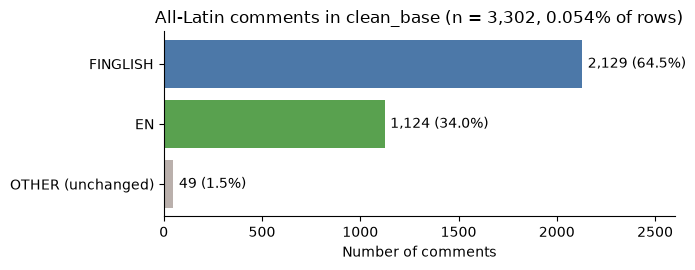

In [4]:
import matplotlib.pyplot as plt
from digikala_review_transformer.config import ROOT

labels = ["FINGLISH", "EN", "OTHER (unchanged)"]
counts = [2129, 1124, 49]

fig, ax = plt.subplots(figsize=(7, 2.8))
bars = ax.barh(labels, counts, color=["#4c78a8", "#59a14f", "#bab0ac"])
ax.bar_label(bars, labels=[f"{c:,} ({c / 3302:.1%})" for c in counts], padding=4)
ax.invert_yaxis()
ax.set_xlim(0, 2600)
ax.set_xlabel("Number of comments")
ax.set_title("All-Latin comments in clean_base (n = 3,302, 0.054% of rows)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(ROOT / "reports" / "latin_conversion_outcome.png", dpi=200)
plt.show()

---

# `max_lengh` Determine

## step 0:
1. Sample: 300,000 random rows from the entire dataset, with seed = 2026.
2. Candidate lengths: 64, 96, 128, 160, 192, 256, 384, 512.
3. Selection criterion: The smallest candidate that accounts for less than 2% of the rows in the distribution of unique bodies (the most conservative of all row sets), provided that the truncation percentage for any single class does not exceed twice the average. The final value is the maximum of the three tokenizers, rounded up to a multiple of 32, with a cap of 512. We also report the distribution for the "all rows" set.
4. Tokenizers: Three project checkpoints (ParsBERT, HooshvareLab/bert-fa-base-uncased, and xlm-roberta-base). If you chose ParsBERT under a different name, please specify it when writing the code.
5. 

### Cell 1: Retrieving a sample from the database

In [16]:
import pandas as pd

SEED = 2026
SAMPLE_N = 300_000
CANDIDATE_LENGTHS = [64, 96, 128, 160, 192, 256, 384, 512]

# Persist the sample as a table so it is reproducible even if sampling order changes
con.execute(f"""
    CREATE OR REPLACE TABLE len_sample AS
    SELECT id, body, recommendation_status, rating_band, product_id
    FROM clean_base
    USING SAMPLE reservoir({SAMPLE_N} ROWS) REPEATABLE ({SEED})
""")

df = con.execute("SELECT * FROM len_sample").df()

n_unique = df["body"].nunique()
print("rows:", len(df))
print("null body:", df["body"].isna().sum())
print("empty/whitespace body:", (df["body"].fillna("").str.strip() == "").sum())
print(f"unique bodies: {n_unique} ({n_unique / len(df):.1%} of rows)")
print()
print(df["recommendation_status"].value_counts(dropna=False, normalize=True).round(4))
print()
print(df["rating_band"].value_counts(dropna=False, normalize=True).round(4))

rows: 300000
null body: 0
empty/whitespace body: 0
unique bodies: 222537 (74.2% of rows)

recommendation_status
recommended        0.6776
NaN                0.1442
no_idea            0.0965
not_recommended    0.0817
Name: proportion, dtype: float64

rating_band
high      0.6509
low       0.1772
medium    0.1719
Name: proportion, dtype: float64


## Cell 2: Load tokenizers from cache

In [18]:
from pathlib import Path
from transformers import AutoTokenizer, AutoConfig

# Find project root
PROJECT_ROOT = Path.cwd().parent

# Models directory
MODELS_DIR = PROJECT_ROOT / "models" / "pretrained"

# Model paths
MODELS = {
    "tooka": MODELS_DIR / "TookaBERT-Base",
    "parsbert3": MODELS_DIR / "roberta-fa-zwnj-base",
    "mdeberta": MODELS_DIR / "mdeberta-v3-base",
}

# Check models directory
if not MODELS_DIR.exists():
    raise FileNotFoundError(
        f"Models directory not found: {MODELS_DIR.resolve()}"
    )

# Contains a ZWNJ (U+200C) in "بسته‌بندی"
example = "کیفیت محصول خیلی خوب بود اما بسته‌بندی ضعیف بود."

tokenizers = {}

for key, path in MODELS.items():

    if not path.exists():
        raise FileNotFoundError(
            f"Model directory not found: {path.resolve()}"
        )

    tok = AutoTokenizer.from_pretrained(
        str(path),
        local_files_only=True
    )

    cfg = AutoConfig.from_pretrained(
        str(path),
        local_files_only=True
    )

    tokenizers[key] = tok

    ids = tok(example)["input_ids"]

    print("=" * 70)
    print(key, "|", path.name)

    print(
        "class:", type(tok).__name__,
        "| fast:", tok.is_fast,
        "| vocab:", len(tok)
    )

    print(
        "model_max_length:", tok.model_max_length,
        "| max_position_embeddings:",
        getattr(cfg, "max_position_embeddings", None)
    )

    print("specials:", tok.special_tokens_map)
    print("tokens:", tok.convert_ids_to_tokens(ids))
    print("n_tokens (with specials):", len(ids))


zwnj_share = df["body"].str.contains(
    "\u200c",
    regex=False
).mean()

print()
print(
    f"share of sampled bodies containing ZWNJ: {zwnj_share:.1%}"
)

tooka | TookaBERT-Base
class: TokenizersBackend | fast: True | vocab: 48000
model_max_length: 512 | max_position_embeddings: 512
specials: {'bos_token': '<s>', 'eos_token': '</s>', 'unk_token': '<unk>', 'sep_token': '</s>', 'pad_token': '<pad>', 'mask_token': '<mask>'}
tokens: ['<s>', '▁کیفیت', '▁محصول', '▁خیلی', '▁خوب', '▁بود', '▁اما', '▁بسته\u200cبندی', '▁ضعیف', '▁بود', '.', '</s>']
n_tokens (with specials): 12
parsbert3 | roberta-fa-zwnj-base
class: RobertaTokenizer | fast: True | vocab: 42000
model_max_length: 512 | max_position_embeddings: 514
specials: {'bos_token': '<s>', 'eos_token': '</s>', 'unk_token': '<unk>', 'sep_token': '</s>', 'pad_token': '<pad>', 'cls_token': '<s>', 'mask_token': '<mask>'}
tokens: ['<s>', 'Ú©ÛĮÙģÛĮØª', 'ĠÙħØŃØµÙĪÙĦ', 'ĠØ®ÛĮÙĦÛĮ', 'ĠØ®ÙĪØ¨', 'ĠØ¨ÙĪØ¯', 'ĠØ§ÙħØ§', 'ĠØ¨Ø³ØªÙĩ', 'âĢĮ', 'Ø¨ÙĨØ¯ÛĮ', 'ĠØ¶Ø¹ÛĮÙģ', 'ĠØ¨ÙĪØ¯', '.', '</s>']
n_tokens (with specials): 14


[transformers] The tokenizer you are loading from '/home/alireza/AI-Bootcamp/Project-3-digikala-review/digikala-review-transformer/models/pretrained/mdeberta-v3-base' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


mdeberta | mdeberta-v3-base
class: DebertaV2Tokenizer | fast: True | vocab: 250102
model_max_length: 1000000000000000019884624838656 | max_position_embeddings: 512
specials: {'bos_token': '[CLS]', 'eos_token': '[SEP]', 'unk_token': '[UNK]', 'sep_token': '[SEP]', 'pad_token': '[PAD]', 'cls_token': '[CLS]', 'mask_token': '[MASK]'}
tokens: ['[CLS]', '▁کی', 'فیت', '▁', 'محصول', '▁خ', 'یلی', '▁', 'خوب', '▁بود', '▁اما', '▁ب', 'سته', '[UNK]', 'بندی', '▁', 'ضع', 'یف', '▁بود', '.', '[SEP]']
n_tokens (with specials): 21

share of sampled bodies containing ZWNJ: 3.1%


## Cell 3: Verification of all three tokenizers

In [23]:
from transformers import AutoTokenizer

texts = df["body"].sample(2000, random_state=2026).tolist()

for key, tok in tokenizers.items():
    enc = tok(texts, add_special_tokens=False)["input_ids"]
    dec = tok.batch_decode(enc, skip_special_tokens=True,
                           clean_up_tokenization_spaces=False)
    n_tok = sum(len(x) for x in enc)
    unk_id = tok.unk_token_id
    n_unk = sum(i == unk_id for x in enc for i in x) if unk_id is not None else 0
    exact = sum(d.strip() == t.strip() for d, t in zip(dec, texts))
    print("=" * 60)
    print(key)
    print(f"round-trip exact: {exact / len(texts):.1%} | "
          f"UNK rate: {n_unk / n_tok:.3%} | tokens/text: {n_tok / len(texts):.1f}")
    print("decode(example):", tok.decode(tok(example)["input_ids"], skip_special_tokens=True))
    bad = [(t, d) for d, t in zip(dec, texts) if d.strip() != t.strip()][:2]
    for t, d in bad:
        print("  orig:", repr(t[:80]))
        print("  back:", repr(d[:80]))

# mdeberta: fast vs slow (slow = reference SentencePiece implementation)
print("=" * 60)
try:
    slow = AutoTokenizer.from_pretrained(
        str(MODELS["mdeberta"]), use_fast=False, local_files_only=True
    )
    print("mdeberta SLOW:", slow.convert_ids_to_tokens(slow(example)["input_ids"]))
    print("mdeberta FAST:", tokenizers["mdeberta"].convert_ids_to_tokens(
        tokenizers["mdeberta"](example)["input_ids"]))
except Exception as e:
    print("slow tokenizer failed:", repr(e))

[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


tooka
round-trip exact: 99.1% | UNK rate: 0.077% | tokens/text: 11.1
decode(example): کیفیت محصول خیلی خوب بود اما بسته‌بندی ضعیف بود.
  orig: 'کیفیتا عاالی😍'
  back: 'کیفیتا عاالی'
  orig: 'تیشرت قشنگی است و مارکش باعث خوشحالی کودکان میشود🙂🙂'
  back: 'تیشرت قشنگی است و مارکش باعث خوشحالی کودکان میشود'
parsbert3
round-trip exact: 100.0% | UNK rate: 0.000% | tokens/text: 11.7
decode(example): کیفیت محصول خیلی خوب بود اما بسته‌بندی ضعیف بود.
mdeberta
round-trip exact: 97.0% | UNK rate: 0.275% | tokens/text: 18.5
decode(example): کیفیت محصول خیلی خوب بود اما بستهبندی ضعیف بود.
  orig: 'کیفیت خوبی دارد وتیزی مناسب. حتی ناخن\u200cهای پارا هم براحتی میگیرد.'
  back: 'کیفیت خوبی دارد وتیزی مناسب. حتی ناخنهای پارا هم براحتی میگیرد.'
  orig: 'خیلی بزرگ بود و به عنوان جا گلدانی فعلا استفاده\u200cاش نکردم ولی گذاشتم بمونه شاید ب'
  back: 'خیلی بزرگ بود و به عنوان جا گلدانی فعلا استفادهاش نکردم ولی گذاشتم بمونه شاید بع'


[transformers] The tokenizer you are loading from '/home/alireza/AI-Bootcamp/Project-3-digikala-review/digikala-review-transformer/models/pretrained/mdeberta-v3-base' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


mdeberta SLOW: ['[CLS]', '▁کی', 'فیت', '▁', 'محصول', '▁خ', 'یلی', '▁', 'خوب', '▁بود', '▁اما', '▁ب', 'سته', '[UNK]', 'بندی', '▁', 'ضع', 'یف', '▁بود', '.', '[SEP]']
mdeberta FAST: ['[CLS]', '▁کی', 'فیت', '▁', 'محصول', '▁خ', 'یلی', '▁', 'خوب', '▁بود', '▁اما', '▁ب', 'سته', '[UNK]', 'بندی', '▁', 'ضع', 'یف', '▁بود', '.', '[SEP]']


## Cell 4: The definitive reference for mDeBERTa

In [24]:
import sentencepiece as spm

sp = spm.SentencePieceProcessor(model_file=str(MODELS["mdeberta"] / "spm.model"))
print("SPM reference:", sp.encode(example, out_type=str))
ref_avg = sum(len(x) for x in sp.encode(texts)) / len(texts)
print(f"SPM tokens/text (no specials): {ref_avg:.1f}  (HF gave 18.5)")

SPM reference: ['▁کی', 'فیت', '▁', 'محصول', '▁خ', 'یلی', '▁', 'خوب', '▁بود', '▁اما', '▁ب', 'سته', '▁بندی', '▁', 'ضع', 'یف', '▁بود', '.']
SPM tokens/text (no specials): 18.5  (HF gave 18.5)


## Cell 5: Calculation of lengths and percentile table

In [25]:
import numpy as np
import pandas as pd

for key, tok in tokenizers.items():
    ids = tok(df["body"].tolist(), add_special_tokens=True, truncation=False)["input_ids"]
    df[f"len_{key}"] = np.array([len(x) for x in ids])
    print(key, "done")

PCTS = [50, 75, 90, 95, 97, 98, 99, 99.5, 99.9, 100]
df_u = df.drop_duplicates("body")

def pct_table(frame):
    return pd.DataFrame(
        {k: np.percentile(frame[f"len_{k}"], PCTS) for k in tokenizers},
        index=[f"p{p}" for p in PCTS],
    ).round(0).astype(int)

print(f"\nALL ROWS (n={len(df)})")
print(pct_table(df))
print(f"\nUNIQUE BODIES (n={len(df_u)})")
print(pct_table(df_u))

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (642 > 512). Running this sequence through the model will result in indexing errors


tooka done


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (653 > 512). Running this sequence through the model will result in indexing errors


parsbert3 done
mdeberta done

ALL ROWS (n=300000)
       tooka  parsbert3  mdeberta
p50        9          9        13
p75       15         16        24
p90       27         28        43
p95       38         39        60
p97       47         48        75
p98       55         57        89
p99       72         74       115
p99.5     92         93       147
p99.9    157        159       250
p100     642        653      1013

UNIQUE BODIES (n=222537)
       tooka  parsbert3  mdeberta
p50       11         12        18
p75       19         19        30
p90       31         32        50
p95       43         44        69
p97       53         54        85
p98       62         63       100
p99       80         81       128
p99.5    101        103       163
p99.9    175        178       280
p100     642        653      1013


## Cell 6: Table of candidates and examination of each class

In [26]:
CANDS = [64, 96, 128, 160, 192, 256, 384, 512]

def lost_pct(x, L):
    return np.maximum(x - L, 0).sum() / x.sum() * 100

rows = []
for key in tokenizers:
    for name, frame in [("all", df), ("unique", df_u)]:
        x = frame[f"len_{key}"].to_numpy()
        for L in CANDS:
            rows.append((key, name, L, (x > L).mean() * 100, lost_pct(x, L)))
cand = pd.DataFrame(rows, columns=["tokenizer", "set", "L", "trunc_rows_%", "tokens_lost_%"])

print("% of rows truncated")
print(cand.pivot_table(index=["set", "L"], columns="tokenizer", values="trunc_rows_%").round(2))
print("\n% of tokens lost")
print(cand.pivot_table(index=["set", "L"], columns="tokenizer", values="tokens_lost_%").round(3))

# Per-class truncation (all rows, labels are exact here)
df["rec_cls"] = df["recommendation_status"].fillna("missing")
for key in tokenizers:
    out = {}
    for L in [64, 96, 128, 192]:
        t = df[f"len_{key}"] > L
        out[L] = pd.concat([
            t.groupby(df["rec_cls"]).mean() * 100,
            t.groupby(df["rating_band"]).mean() * 100,
            pd.Series({"OVERALL": t.mean() * 100}),
        ])
    print(f"\n{key}: % rows truncated by class")
    print(pd.DataFrame(out).round(2))

% of rows truncated
tokenizer   mdeberta  parsbert3  tooka
set    L                              
all    64       4.32       1.43   1.36
       96       1.62       0.45   0.43
       128      0.73       0.20   0.19
       160      0.39       0.10   0.09
       192      0.23       0.06   0.05
       256      0.09       0.02   0.02
       384      0.03       0.01   0.00
       512      0.01       0.00   0.00
unique 64       5.81       1.93   1.83
       96       2.18       0.61   0.57
       128      0.99       0.26   0.25
       160      0.52       0.13   0.13
       192      0.31       0.08   0.07
       256      0.13       0.03   0.03
       384      0.04       0.01   0.01
       512      0.01       0.00   0.00

% of tokens lost
tokenizer   mdeberta  parsbert3  tooka
set    L                              
all    64      8.170      3.512  3.453
       96      3.971      1.547  1.529
       128     2.252      0.832  0.823
       160     1.421      0.502  0.498
       192     0.956      

## Cell 7: Check 160 for mdeberta

In [27]:
for L in [128, 160, 192]:
    t = df["len_mdeberta"] > L
    s = pd.concat([t.groupby(df["rec_cls"]).mean() * 100,
                   t.groupby(df["rating_band"]).mean() * 100])
    overall = t.mean() * 100
    print(f"L={L}: overall={overall:.2f}% | worst class: {s.idxmax()} "
          f"{s.max():.2f}% | ratio={s.max() / overall:.2f}x")

L=128: overall=0.73% | worst class: not_recommended 1.53% | ratio=2.09x
L=160: overall=0.39% | worst class: not_recommended 0.74% | ratio=1.91x
L=192: overall=0.23% | worst class: not_recommended 0.41% | ratio=1.80x


---

# frequent words and bigrams

In [1]:
import json, shutil, hashlib
from pathlib import Path

import duckdb
import pandas as pd

from digikala_review_transformer.config import (
    ROOT, DB_PATH, CLEAN_TABLE,
    DATA_INTERIM, DATA_PROCESSED, REPORTS,
    SPLIT_SEED, MASK_SEED, MASK_RATE,
)

con = duckdb.connect(str(DB_PATH))
cur = con.cursor()

def scalar(query, *params):
    """Run a query and return the first cell of the first row."""
    return cur.execute(query, list(params)).fetchone()[0]

In [2]:
import re
from collections import Counter, defaultdict

TEXT_COL = "body"
LABEL_COL = "recommendation_status"
CHUNK = 100_000
MAX_ROWS = 500_000        # None = کل داده

TOKEN_RE = re.compile(r"[\u0621-\u064A\u067E\u0686\u0698\u06A9\u06AF\u06CC\u200c]+")

def tokenize(text):
    toks = [t.strip("\u200c") for t in TOKEN_RE.findall(text)]
    return [t for t in toks if len(t) > 1]

# نمونه‌گیری قطعی: ترتیب بر اساس هش md5(id + seed)، سپس N ردیف اول
# اگر MAX_ROWS=None باشد، کل داده بدون ترتیب‌دهی خوانده می‌شود
if MAX_ROWS:
    sql = f"""
        SELECT {TEXT_COL}, COALESCE(CAST({LABEL_COL} AS VARCHAR), 'unlabeled') AS label
        FROM {CLEAN_TABLE}
        WHERE {TEXT_COL} IS NOT NULL
        ORDER BY md5(CAST(id AS VARCHAR) || '|{SPLIT_SEED}')
        LIMIT {MAX_ROWS}
    """
else:
    sql = f"""
        SELECT {TEXT_COL}, COALESCE(CAST({LABEL_COL} AS VARCHAR), 'unlabeled') AS label
        FROM {CLEAN_TABLE}
        WHERE {TEXT_COL} IS NOT NULL
    """

uni = defaultdict(Counter)   # uni[label][word]
bi  = defaultdict(Counter)   # bi[label][(w1, w2)]
n_docs = Counter()

cur.execute(sql)
seen = 0
while True:
    rows = cur.fetchmany(CHUNK)
    if not rows:
        break
    for text, lab in rows:
        toks = tokenize(str(text))
        n_docs[lab] += 1
        uni[lab].update(toks)
        bi[lab].update(zip(toks, toks[1:]))   # بایگرام فقط داخل یک نظر
    seen += len(rows)
    print(f"{seen:,} rows done")

labels = sorted(uni.keys())
print(labels, dict(n_docs))

100,000 rows done
200,000 rows done
300,000 rows done
400,000 rows done
500,000 rows done
['no_idea', 'not_recommended', 'recommended', 'unlabeled'] {'not_recommended': 41194, 'recommended': 337670, 'no_idea': 48486, 'unlabeled': 72650}


## Cell 2 — Aggregation and Filtered View

In [3]:
# Stopwords are a supplementary view only (an experiment); negation words are intentionally excluded
STOP = set("""از به در با که این آن را و برای هم تا یک من ما شما او هر اما یا
چون اگر پس بر نیز همه خیلی""".split())

def merge(counters_by_label):
    total = Counter()
    for c in counters_by_label.values():
        total.update(c)
    out = dict(counters_by_label)
    out["all"] = total
    return out

U = merge(uni)
B = merge(bi)

def top(counter, k=30, filtered=False, is_bigram=False):
    items = counter.items()
    if filtered:
        if is_bigram:
            items = [(g, c) for g, c in items if not (g[0] in STOP and g[1] in STOP)]
        else:
            items = [(w, c) for w, c in items if w not in STOP]
    items = sorted(items, key=lambda x: -x[1])[:k]
    names = [" ".join(g) if is_bigram else g for g, _ in items]
    return names[::-1], [c for _, c in items][::-1]   # reversed so the largest bar is on top

## Cell 3 — Creating Interactive HTML and Saving

In [4]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

OUT_DIR = REPORTS / "vocab_analysis"
OUT_DIR.mkdir(parents=True, exist_ok=True)

FONT = "Vazirmatn, Tahoma, 'Segoe UI', sans-serif"
groups = ["all"] + labels
views = [(g, f) for g in groups for f in (False, True)]   # (group, stopword_filtered)

def view_name(g, f):
    return f"{g} | {'no stopwords' if f else 'raw'}"

fig = make_subplots(rows=1, cols=2, horizontal_spacing=0.18,
                    subplot_titles=("Top words", "Top bigrams"))

for i, (g, f) in enumerate(views):
    for col, (src, isb) in enumerate([(U, False), (B, True)], start=1):
        y, x = top(src[g], 30, f, isb)
        fig.add_trace(go.Bar(
            x=x, y=y, orientation="h", visible=(i == 0),
            marker=dict(color=x, colorscale="Tealgrn" if col == 1 else "Sunsetdark"),
            hovertemplate="%{y}<br>count: %{x:,}<extra></extra>",
            showlegend=False), row=1, col=col)

buttons = []
for i, (g, f) in enumerate(views):
    vis = [False] * (2 * len(views))
    vis[2 * i] = vis[2 * i + 1] = True
    name = view_name(g, f)
    buttons.append(dict(label=name, method="update",
                        args=[{"visible": vis}, {"title": f"Vocabulary analysis | {name}"}]))

fig.update_layout(
    title=f"Vocabulary analysis | {view_name(*views[0])}",
    updatemenus=[dict(buttons=buttons, x=0.0, y=1.18, xanchor="left")],
    template="plotly_white", font=dict(family=FONT, size=13),
    height=900, margin=dict(l=20, r=20, t=130, b=40))

fig.write_html(OUT_DIR / "frequent_terms.html", include_plotlyjs=True)
fig.show()

## Cell 4 — "Distinguishing" words and bigrams for each class (much more useful)

In [5]:
import numpy as np
import pandas as pd

def distinctive(cnt_a, cnt_b, min_count=30, k=25, alpha=1.0, is_bigram=False):
    na, nb = sum(cnt_a.values()), sum(cnt_b.values())
    rows = []
    for key in set(cnt_a) | set(cnt_b):
        a, b = cnt_a.get(key, 0), cnt_b.get(key, 0)
        if a + b < min_count:
            continue
        score = np.log((a + alpha) / (na + alpha)) - np.log((b + alpha) / (nb + alpha))
        name = " ".join(key) if is_bigram else key
        rows.append((name, round(float(score), 3), a, b))
    rows.sort(key=lambda r: -r[1])
    return rows[:k], rows[-k:][::-1]

print("labels:", labels)
POS, NEG = "recommended", "not_recommended"
assert POS in B and NEG in B, "class names do not match `labels`"

pos_bi, neg_bi = distinctive(B[POS], B[NEG], min_count=30, k=25, is_bigram=True)
pos_uni, neg_uni = distinctive(U[POS], U[NEG], min_count=30, k=25, is_bigram=False)

# ---- CSV ----
cols = ["term", "log_odds", "count_pos", "count_neg"]
parts = []
for rows, unit, side in [(pos_bi, "bigram", POS), (neg_bi, "bigram", NEG),
                         (pos_uni, "word", POS), (neg_uni, "word", NEG)]:
    d = pd.DataFrame(rows, columns=cols)
    d["unit"], d["side"] = unit, side
    parts.append(d)
distinct_df = pd.concat(parts, ignore_index=True)
distinct_df.to_csv(OUT_DIR / "distinctive_terms.csv", index=False, encoding="utf-8-sig")

# ---- Diverging bar HTML ----
fig2 = go.Figure()
units = ["bigram", "word"]
for u in units:
    d = distinct_df[distinct_df["unit"] == u].sort_values("log_odds")   # most positive ends up on top
    for side, color in [(POS, "#2a9d8f"), (NEG, "#e76f51")]:
        s = d[d["side"] == side]
        fig2.add_trace(go.Bar(
            x=s["log_odds"], y=s["term"], orientation="h", name=side,
            marker_color=color, visible=(u == units[0]),
            customdata=s[["count_pos", "count_neg"]].values,
            hovertemplate=("%{y}<br>log-odds: %{x}<br>"
                           f"{POS}: " "%{customdata[0]:,}<br>"
                           f"{NEG}: " "%{customdata[1]:,}<extra></extra>")))

buttons = []
for i, u in enumerate(units):
    vis = [False] * (2 * len(units))
    vis[2 * i] = vis[2 * i + 1] = True
    buttons.append(dict(label=u, method="update",
                        args=[{"visible": vis}, {"title": f"Most distinctive {u}s: {POS} vs {NEG}"}]))

fig2.update_layout(
    title=f"Most distinctive bigrams: {POS} vs {NEG}",
    xaxis_title=f"log-odds  (right = more typical of {POS}, left = more typical of {NEG})",
    updatemenus=[dict(buttons=buttons, x=0.0, y=1.12, xanchor="left")],
    template="plotly_white", font=dict(family=FONT, size=13),
    barmode="relative", height=1000, margin=dict(l=20, r=20, t=110, b=40))

fig2.write_html(OUT_DIR / "distinctive_terms.html", include_plotlyjs=True)
fig2.show()
print("saved to:", OUT_DIR)

labels: ['no_idea', 'not_recommended', 'recommended', 'unlabeled']


saved to: /home/alireza/AI-Bootcamp/Project-3-digikala-review/digikala-review-transformer/reports/vocab_analysis
